Abstract

Эдийн засгийн хөгжил ба Хуванцар хог хаягдлын бүтэц:
Энэ асуулт нь "Улс орнууд хөгжих тусам хэрэглээний хэв маяг нь өөрчлөгдөж, хуванцар хаягдлын эзлэх хувь нэмэгддэг үү?" гэдгийг шалгана. Цаашид хүнсний хаягдал (composition_food_organic_waste_percent) эсвэл дахин боловсруулалттай (waste_treatment_recycling_percent) харьцуулахад маш гоё уялдана.
* (Research Question):
Улс орнуудын орлогын түвшингээс (income_id: HIC, UMC, LMC, LIC) хамаарч нийт хог хаягдалд эзлэх хуванцар хог хаягдлын дундаж хувь (composition_plastic_percent) статистик ач холбогдол бүхий ялгаатай байна уу?
* H_0 (Null Hypothesis):
Бүх орлогын түвшний бүлгүүдэд (HIC, UMC, LMC, LIC) хуванцар хог хаягдлын дундаж хувь ижил байна (\mu_{HIC} = \mu_{UMC} = \mu_{LMC} = \mu_{LIC}).
* H_1 (Alternative Hypothesis):
Дор хаяж нэг орлогын бүлгийн хуванцар хог хаягдлын дундаж хувь бусдаасаа статистик ач холбогдол бүхий ялгаатай байна.
* Ашиглах тест: Тархалтаас хамааран One-Way ANOVA (хэвийн тархалттай бол) болон Shapiro-Wilk тест (хэвийн тархалттай бол), дараа нь аль бүлгүүд ялгаатайг харах Post-hoc тест.

PART A: Reading the data in Python

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df= pd.read_csv('country_level_data.csv')

In [3]:
df["msw_pc"] = (df["total_msw_total_msw_generated_tons_year"] * 1000/ 365/ df["population_population_number_of_people"])
print(df["msw_pc"].describe())

count    215.000000
mean       1.034366
std        0.714133
min        0.102384
25%        0.464641
50%        0.875000
75%        1.386628
max        3.794240
Name: msw_pc, dtype: float64


In [4]:
df=df.drop_duplicates()
print('Shape After deleting duplicate values:', df.shape)
df.head(10)

Shape After deleting duplicate values: (217, 52)


,iso3c,region_id,country_name,income_id,gdp,composition_food_organic_waste_percent,composition_glass_percent,composition_metal_percent,composition_other_percent,composition_paper_cardboard_percent,...,waste_treatment_incineration_percent,waste_treatment_landfill_unspecified_percent,waste_treatment_open_dump_percent,waste_treatment_other_percent,waste_treatment_recycling_percent,waste_treatment_sanitary_landfill_landfill_gas_system_percent,waste_treatment_unaccounted_for_percent,waste_treatment_waterways_marine_percent,where_where_is_this_data_measured,msw_pc
0,ABW,LCN,Aruba,HIC,35563.312500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,11.0,NaN,89.00,NaN,NaN,2.340000
1,AFG,SAS,Afghanistan,LIC,2057.062256,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Other,0.444962
2,AGO,SSF,Angola,LMC,8036.690430,51.80,6.70,4.40,11.50,11.90,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.460000
3,ALB,ECS,Albania,UMC,13724.058590,51.40,4.50,4.80,15.21,9.90,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Some disposal sites,1.043836
4,AND,ECS,Andorra,HIC,43711.800780,31.20,8.20,2.60,11.60,35.10,...,52.1,NaN,NaN,NaN,NaN,NaN,47.90,NaN,NaN,1.429174
5,ARE,MEA,United Arab Emirates,HIC,67119.132810,39.00,4.00,3.00,10.00,25.00,...,NaN,9.0,62.0,NaN,20.0,NaN,NaN,NaN,NaN,1.575238
6,ARG,LCN,Argentina,HIC,23550.099610,38.74,3.16,1.84,15.36,13.96,...,NaN,NaN,22.6,NaN,6.0,62.5,NaN,NaN,Other,1.141654
7,ARM,ECS,Armenia,UMC,11019.838870,57.00,3.20,3.40,17.40,6.70,...,NaN,NaN,100.0,NaN,NaN,NaN,NaN,NaN,Other,0.464568
8,ASM,EAS,American Samoa,UMC,11113.442380,19.70,3.40,7.90,25.60,26.40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.935736
9,ATG,LCN,Antigua and Barbuda,HIC,17965.501950,46.00,7.00,7.00,12.00,15.00,...,NaN,NaN,NaN,NaN,NaN,NaN,1.14,0.1,Disposal Site,0.865852


Defining the problem statement



In [5]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 52 columns):
 #   Column                                                                                 Non-Null Count  Dtype  
---  ------                                                                                 --------------  -----  
 0   iso3c                                                                                  217 non-null    str    
 1   region_id                                                                              217 non-null    str    
 2   country_name                                                                           216 non-null    str    
 3   income_id                                                                              217 non-null    str    
 4   gdp                                                                                    216 non-null    float64
 5   composition_food_organic_waste_percent                                                 17

In [6]:
df.nunique()

iso3c                                                                                    217
region_id                                                                                  7
country_name                                                                             216
income_id                                                                                  4
gdp                                                                                      213
composition_food_organic_waste_percent                                                   135
composition_glass_percent                                                                 91
composition_metal_percent                                                                 83
composition_other_percent                                                                127
composition_paper_cardboard_percent                                                      124
composition_plastic_percent                                           

Removing useless columns from the data

In [7]:
columns_to_keep = [
    'country_name', 
    'iso3c', 
    'region_id', 
    'income_id', 
    'gdp', 
    'msw_pc', 
    'composition_plastic_percent', 
    'composition_food_organic_waste_percent', 
    'composition_paper_cardboard_percent', 
    'waste_treatment_recycling_percent', 
    'other_information_ppp_rules_and_regulations',
    'total_msw_total_msw_generated_tons_year',
    'population_population_number_of_people'
]
existing_columns = [col for col in columns_to_keep if col in df.columns]
df = df[existing_columns]

print(f"Number of remaining column: {df.shape[1]}")
print("The remaining columns:", df.columns.tolist())

Number of remaining column: 13
The remaining columns: ['country_name', 'iso3c', 'region_id', 'income_id', 'gdp', 'msw_pc', 'composition_plastic_percent', 'composition_food_organic_waste_percent', 'composition_paper_cardboard_percent', 'waste_treatment_recycling_percent', 'other_information_ppp_rules_and_regulations', 'total_msw_total_msw_generated_tons_year', 'population_population_number_of_people']


Data Cleaning and Processing

In [8]:
[print(col, df[col].unique()) for col in ['country_name','gdp', 'total_msw_total_msw_generated_tons_year']]

country_name <ArrowStringArray>
[                 'Aruba',            'Afghanistan',                 'Angola',
                'Albania',                'Andorra',   'United Arab Emirates',
              'Argentina',                'Armenia',         'American Samoa',
    'Antigua and Barbuda',
 ...
 'British Virgin Islands',  'Virgin Islands (U.S.)',                'Vietnam',
                'Vanuatu',                  'Samoa',                 'Kosovo',
            'Yemen, Rep.',           'South Africa',                 'Zambia',
               'Zimbabwe']
Length: 217, dtype: str
gdp [ 35563.3125      2057.062256    8036.69043    13724.05859
  43711.80078    67119.13281    23550.09961    11019.83887
  11113.44238    17965.50195    47784.17969    56029.61328
  14853.91016      839.7785034  51914.91406     2227.352295
   1925.331177    3195.737061   22279.36133    47937.77734
  35400.08203    12671.00781    18307.51953     7259.024414
  80982.36719     7984.413574   14596.24609    1544

[None, None, None]

In [9]:
df.info()
print("Missing value:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 13 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   country_name                                 216 non-null    str    
 1   iso3c                                        217 non-null    str    
 2   region_id                                    217 non-null    str    
 3   income_id                                    217 non-null    str    
 4   gdp                                          216 non-null    float64
 5   msw_pc                                       215 non-null    float64
 6   composition_plastic_percent                  175 non-null    float64
 7   composition_food_organic_waste_percent       176 non-null    float64
 8   composition_paper_cardboard_percent          176 non-null    float64
 9   waste_treatment_recycling_percent            125 non-null    float64
 10  other_informa

In [10]:
missing_rows = df[
    df["country_name"].isnull()
    | df["gdp"].isnull()
    | df["total_msw_total_msw_generated_tons_year"].isnull()
]
display(missing_rows)

,country_name,iso3c,region_id,income_id,gdp,msw_pc,composition_plastic_percent,composition_food_organic_waste_percent,composition_paper_cardboard_percent,waste_treatment_recycling_percent,other_information_ppp_rules_and_regulations,total_msw_total_msw_generated_tons_year,population_population_number_of_people
183,Sint Maarten (Dutch part),SXM,LCN,HIC,NaN,NaN,13.00,46.00,15.00,NaN,NaN,NaN,37685
186,Turks and Caicos Islands,TCA,LCN,HIC,28174.48242,NaN,16.30,21.80,31.50,NaN,Yes,NaN,34900
198,NaN,TWN,EAS,HIC,57362.92578,0.85767,20.23,23.34,30.01,NaN,Yes,7336000.0,23434000


In [11]:
df.loc[df['country_name'].isnull() & (df['iso3c'] == 'TWN'), 'country_name'] = 'Taiwan'

In [13]:
str_cols = df.select_dtypes(include=['str', 'object']).columns
for col in str_cols:
    # 1. incorrect values to NaN 
    df[col] = df[col].replace(
        to_replace=[r'^\s*$', r'^(None|none|NONE|nan|NaN|NAN|null|NULL)$'],
        value=np.nan,
        regex=True
    )
    # 2.Remove excess white space
    df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)
# 5. after fixed str missing 
print("\nstr Nan:")
print(df[str_cols].isnull().sum())


str Nan:
country_name                                    0
iso3c                                           0
region_id                                       0
income_id                                       0
other_information_ppp_rules_and_regulations    59
dtype: int64


In [14]:
float_cols = ['gdp','composition_plastic_percent',
    'composition_food_organic_waste_percent',
    'composition_paper_cardboard_percent',
    'waste_treatment_recycling_percent',
    'total_msw_total_msw_generated_tons_year']
for col in float_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '', regex=False).str.strip(),
        errors='coerce'
    ).astype('float64')

In [15]:
missing_rows = df[
    df["composition_plastic_percent"].isnull()
    | df["composition_food_organic_waste_percent"].isnull()
    | df["composition_paper_cardboard_percent"].isnull()
    | df["waste_treatment_recycling_percent"].isnull()
    | df["other_information_ppp_rules_and_regulations"].isnull()]
display(missing_rows)

,country_name,iso3c,region_id,income_id,gdp,msw_pc,composition_plastic_percent,composition_food_organic_waste_percent,composition_paper_cardboard_percent,waste_treatment_recycling_percent,other_information_ppp_rules_and_regulations,total_msw_total_msw_generated_tons_year,population_population_number_of_people
0,Aruba,ABW,LCN,HIC,35563.312500,2.340000,NaN,NaN,NaN,11.0,Yes,8.813202e+04,103187
1,Afghanistan,AFG,SAS,LIC,2057.062256,0.444962,NaN,NaN,NaN,NaN,Yes,5.628525e+06,34656032
2,Angola,AGO,SSF,LMC,8036.690430,0.460000,13.500000,51.800000,11.900000,NaN,Yes,4.213644e+06,25096150
3,Albania,ALB,ECS,UMC,13724.058590,1.043836,9.600000,51.400000,9.900000,NaN,Yes,1.087447e+06,2854191
4,Andorra,AND,ECS,HIC,43711.800780,1.429174,11.300000,31.200000,35.100000,NaN,Yes,4.300000e+04,82431
...,...,...,...,...,...,...,...,...,...,...,...,...,...
208,Virgin Islands (U.S.),VIR,LCN,HIC,30436.564450,3.794240,13.000000,46.000000,15.000000,NaN,Yes,1.465000e+05,105784
212,Kosovo,XKX,ECS,LMC,9723.561523,0.485055,11.000000,42.000000,8.000000,NaN,Yes,3.190000e+05,1801800
214,South Africa,ZAF,SSF,UMC,12666.607420,0.977545,7.090104,16.381655,9.396918,28.0,NaN,1.845723e+07,51729344
215,Zambia,ZMB,SSF,LMC,3201.289307,0.500951,NaN,NaN,NaN,NaN,NaN,2.608268e+06,14264756


In [16]:
lcn_hic_median = df[(df['region_id'] == 'LCN') & (df['income_id'] == 'HIC')]['gdp'].median()
df.loc[df['iso3c'] == 'SXM', 'gdp'] = lcn_hic_median

In [17]:
df_plastic = df.dropna(subset=['income_id', 'composition_plastic_percent']).copy()
df_plastic = df_plastic[
    (df_plastic['composition_plastic_percent'] >= 0) & 
    (df_plastic['composition_plastic_percent'] <= 100)]
valid_incomes = ['HIC', 'UMC', 'LMC', 'LIC']
df_plastic = df_plastic[df_plastic['income_id'].isin(valid_incomes)]

print("Total columns:", len(df_plastic))
print("Number of data points in each group:")
print(df_plastic['income_id'].value_counts())
print("Distribution overview:")
print(df_plastic.groupby('income_id')['composition_plastic_percent'].describe())

Total columns: 175
Number of data points in each group:
income_id
HIC    74
UMC    49
LMC    35
LIC    17
Name: count, dtype: int64
Distribution overview:
           count       mean       std   min  25%     50%     75%    max
income_id                                                              
HIC         74.0  12.448919  6.107891  1.00  9.0  12.265  15.965  32.00
LIC         17.0   7.972941  5.381956  2.00  4.0   7.300  10.000  23.00
LMC         35.0  11.109801  5.539365  2.50  7.0  10.550  14.100  26.17
UMC         49.0  12.333692  4.556192  2.19  9.8  12.330  15.000  25.00


In [18]:
from scipy import stats

order = ['LIC', 'LMC', 'UMC', 'HIC']
groups = {name: df_plastic[df_plastic['income_id'] == name]['composition_plastic_percent'].dropna()
    for name in order}
print("(Shapiro-Wilk, p > 0.05)")
for name, series in groups.items():
    stat, p_val = stats.shapiro(series)
    result = "Normal" if p_val > 0.05 else "Abnormal"
    print(f"{name}: W={stat:.4f}, p={p_val:.4f} ({result})")

(Shapiro-Wilk, p > 0.05)
LIC: W=0.8860, p=0.0398 (Abnormal)
LMC: W=0.9641, p=0.3026 (Normal)
UMC: W=0.9806, p=0.5907 (Normal)
HIC: W=0.9741, p=0.1329 (Normal)


In [19]:
f_stat, p_anova = stats.f_oneway(*groups.values())
print("Hypothesis testing tests")
print(f"One-Way ANOVA: F={f_stat:.4f}, p={p_anova:.4f}")

Hypothesis testing tests
One-Way ANOVA: F=3.3752, p=0.0197


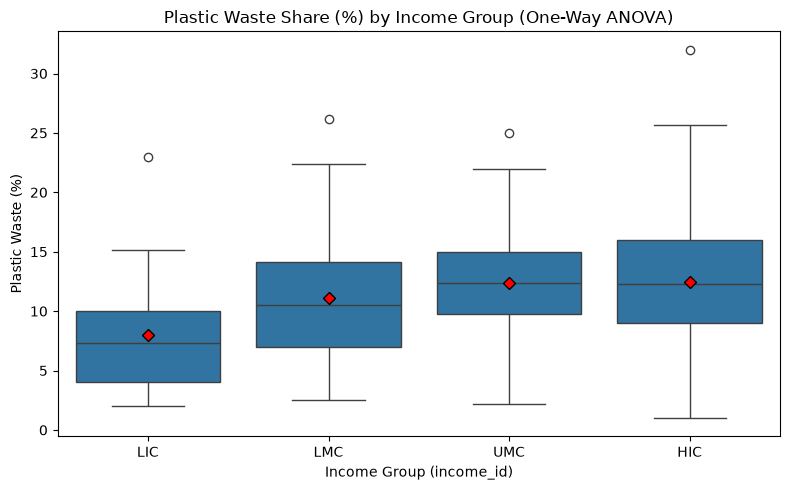

In [20]:
order = ['LIC', 'LMC', 'UMC', 'HIC']
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_plastic,
    x='income_id',
    y='composition_plastic_percent',
    order=order,
    showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': 'red', 'markeredgecolor': 'black', 'markersize': 6})
plt.title('Plastic Waste Share (%) by Income Group (One-Way ANOVA)')
plt.xlabel('Income Group (income_id)')
plt.ylabel('Plastic Waste (%)')
plt.tight_layout()
plt.show()

* Outliers were inspected and kept because they are real observations